# Étape 2 — Comprendre la Data Augmentation

**Termes techniques :** Data Augmentation, RandomFlip, RandomRotation, RandomZoom, RandomTranslation, RandomContrast


## Cellule 1 — Charger les manifestes du notebook précédent


In [1]:
from pathlib import Path
import sys
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
while PROJECT_DIR != PROJECT_DIR.parent and not (PROJECT_DIR / "data" / "split" / "train.csv").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
SPLIT_DIR = PROJECT_DIR / "data" / "split"
sys.path.insert(0, str(PROJECT_DIR))
from src.data_pipeline import load_manifest, make_augmentation

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42
train_table = pd.read_csv(SPLIT_DIR / "train.csv")
class_names = sorted(train_table["label"].unique())
class_to_id = {name: index for index, name in enumerate(class_names)}
train_ds = load_manifest(SPLIT_DIR / "train.csv", class_to_id, IMG_SIZE, BATCH_SIZE, shuffle=True, seed=SEED)
val_ds = load_manifest(SPLIT_DIR / "validation.csv", class_to_id, IMG_SIZE, BATCH_SIZE)
test_ds = load_manifest(SPLIT_DIR / "test.csv", class_to_id, IMG_SIZE, BATCH_SIZE)


## Cellule 2 — Définir des transformations modérées


In [2]:
augmentation = make_augmentation(SEED)

images, labels = next(iter(train_ds))
augmented_images = augmentation(images[:6], training=True)
print("Forme originale :", images[:6].shape)
print("Forme augmentée :", augmented_images.shape)
print("Les labels restent inchangés :", labels[:6].numpy())

Forme originale : (6, 150, 150, 3)
Forme augmentée : (6, 150, 150, 3)
Les labels restent inchangés : [2 4 3 0 5 1]


## Cellule 3 — Voir les images avant et après


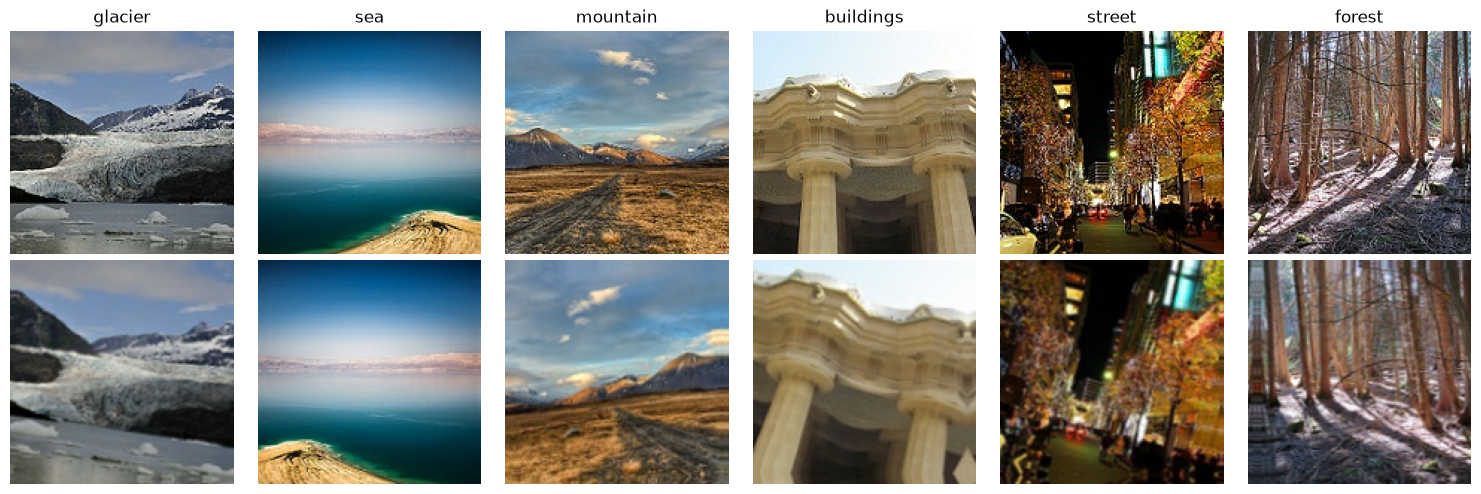

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for column in range(6):
    axes[0, column].imshow(images[column].numpy())
    axes[0, column].set_title(class_names[int(labels[column])])
    axes[1, column].imshow(tf.clip_by_value(augmented_images[column], 0, 1).numpy())
    axes[0, column].axis("off")
    axes[1, column].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Augmentée")
plt.tight_layout()
plt.show()

## Vérification
